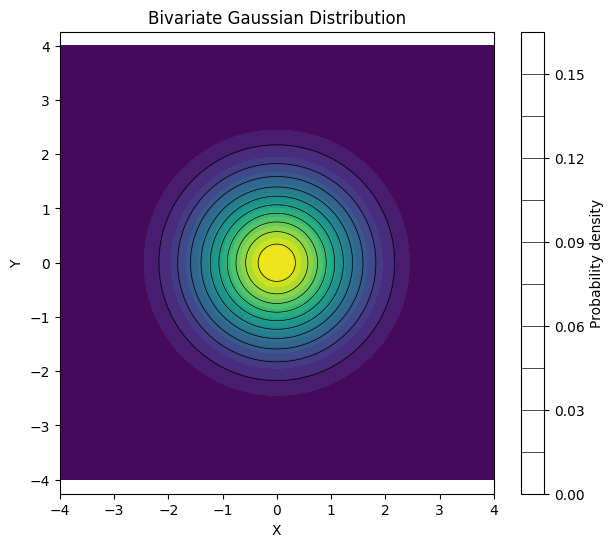

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal

# Mean vector
mu = np.array([0, 0])

# Covariance matrix
Sigma = np.array([
    [1.0, 0],
    [0, 1.0]
])

# Create grid
x = np.linspace(-4, 4, 200)
y = np.linspace(-4, 4, 200)
X, Y = np.meshgrid(x, y)

pos = np.dstack((X, Y))

# Multivariate Gaussian density
rv = multivariate_normal(mean=mu, cov=Sigma)
Z = rv.pdf(pos)

# Plot contour
plt.figure(figsize=(7, 6))
plt.contourf(X, Y, Z, levels=20)
plt.contour(X, Y, Z, levels=10, colors="black", linewidths=0.5)
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Bivariate Gaussian Distribution")
plt.colorbar(label="Probability density")
plt.axis("equal")
plt.show()

In [6]:
def plot_multivariable_gauss_distribution(mu, sigma, title):
    x = np.linspace(-1, 1, 200)
    y = np.linspace(-1, 1, 200)
    X, Y = np.meshgrid(x, y)

    pos = np.dstack((X, Y))

    # Multivariate Gaussian density
    rv = multivariate_normal(mean=mu, cov=sigma)
    Z = rv.pdf(pos)

    # Plot contour
    plt.figure(figsize=(7, 6))
    plt.contourf(X, Y, Z, levels=20)
    plt.contour(X, Y, Z, levels=10, colors="black", linewidths=0.5)
    plt.xlabel("θ0")
    plt.ylabel("θ1")
    plt.title(title)
    plt.colorbar(label="Probability density")
    plt.axis("equal")
    plt.show()

In [7]:
# Generate a synthetic data as a linear regression model: y = 0.3 + 0.5x with noise
def normal_distribution(x,expected, variance):
    denominator_1 = variance* np.sqrt(2*np.pi)
    numerator_1 = (x - expected)**2
    denominator_2 = 2*variance**2
    return (1/denominator_1)*np.exp(- numerator_1/denominator_2) 

def linear_model(x, var, param1 = 0.3, param2 = 0.5):
    noise = np.random.normal(0, var, 1)
    return param1 + param2*x + noise

In [30]:
def calculate_likelihood_distribution(x_list, var, pram1, param2):
    mu = np.array([pram1+ param2*x for x in x_list])
    sigma = np.eye(len(x_list))
    sigma *= var
    return mu, sigma

import numpy as np
import matplotlib.pyplot as plt

def calculate_posterior_distribution(x_list, y_list, mu, sigma, var):
    x = np.asarray(x_list, dtype=float).reshape(-1, 1)    # (n,1)
    y = np.asarray(y_list, dtype=float).reshape(-1, 1)    # (n,1)
    mu = np.asarray(mu, dtype=float).reshape(-1, 1)       # (2,1)
    sigma = np.asarray(sigma, dtype=float)                # (2,2)

    Phi = np.hstack([np.ones_like(x), x])                 # (n,2): [1, x_i]
    sigma_inv = np.linalg.inv(sigma)

    new_sigma = np.linalg.inv(sigma_inv + Phi.T @ Phi / var)          # (2,2)
    new_mu = new_sigma @ (sigma_inv @ mu + Phi.T @ y / var)           # (2,1)
    return new_mu, new_sigma

def likelihood(x_list, y_list, var, param1, param2, log=False):
    x = np.asarray(x_list, dtype=float)
    y = np.asarray(y_list, dtype=float)
    t0 = np.asarray(param1, dtype=float)
    t1 = np.asarray(param2, dtype=float)

    n = len(x)
    # residual: shape (*theta.shape, n)
    resid = y - (t0[..., None] + t1[..., None] * x)
    sse = np.sum(resid ** 2, axis=-1)

    log_lik = -0.5 * n * np.log(2 * np.pi * var) - sse / (2 * var)
    return log_lik if log else np.exp(log_lik)

def plot_likelihood(x_list, y_list, var, title):
    t0, t1 = np.meshgrid(np.linspace(-1, 1, 200), np.linspace(-1, 1, 200))
    L = likelihood(x_list, y_list, var, t0, t1)
    plt.imshow(L, extent=[-1, 1, -1, 1], origin="lower", cmap="jet")
    plt.title(title)
    plt.xlabel("θ0"); plt.ylabel("θ1"); plt.show()

def plot_data_space(x_list, y_list, mu, sigma, n_lines=6, seed=0):
    rng = np.random.default_rng(seed)
    thetas = rng.multivariate_normal(np.ravel(mu), sigma, size=n_lines)  # (n_lines, 2)
    xs = np.linspace(-1, 1, 100)
    plt.figure(figsize=(5, 5))
    for t0, t1 in thetas:
        plt.plot(xs, t0 + t1 * xs, "r")
    if len(x_list) > 0:
        plt.scatter(x_list, np.ravel(y_list), facecolors="none", edgecolors="b")
    plt.xlim(-1, 1); plt.ylim(-1, 1)
    plt.xlabel("x"); plt.ylabel("y")
    plt.show()

# prior: plot_data_space([], [], mu, sigma)
# posterior: plot_data_space(x, y, new_mu, new_sigma)

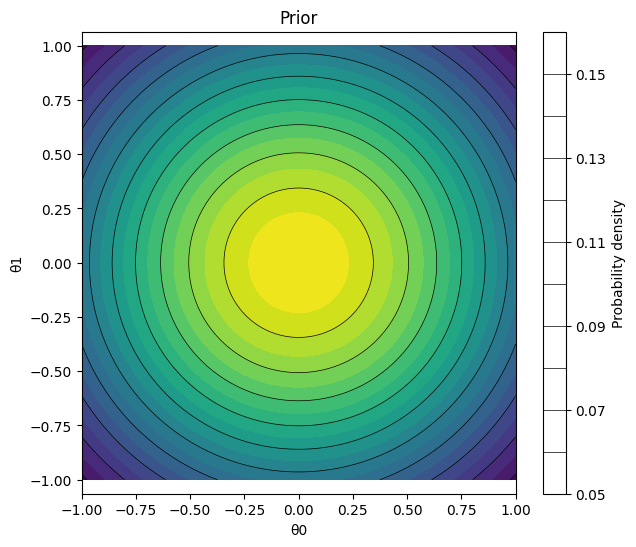

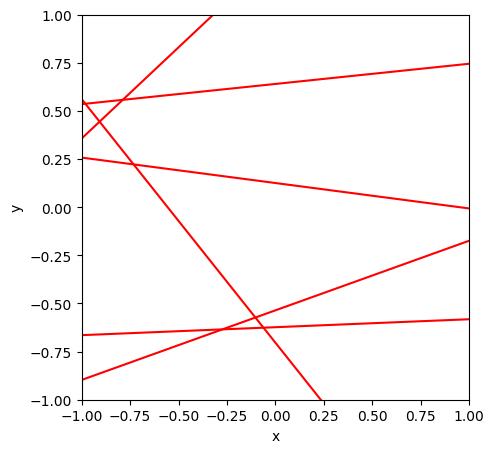

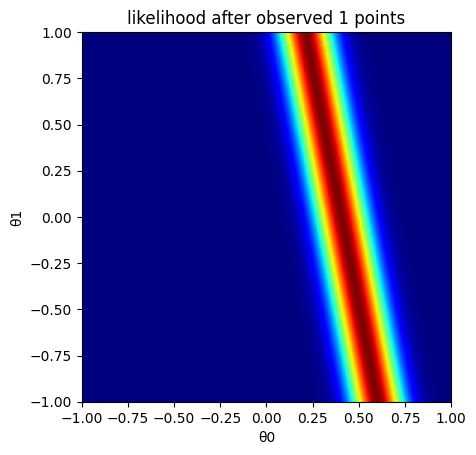

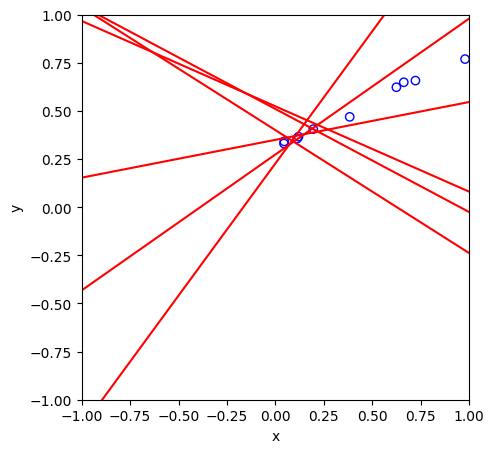

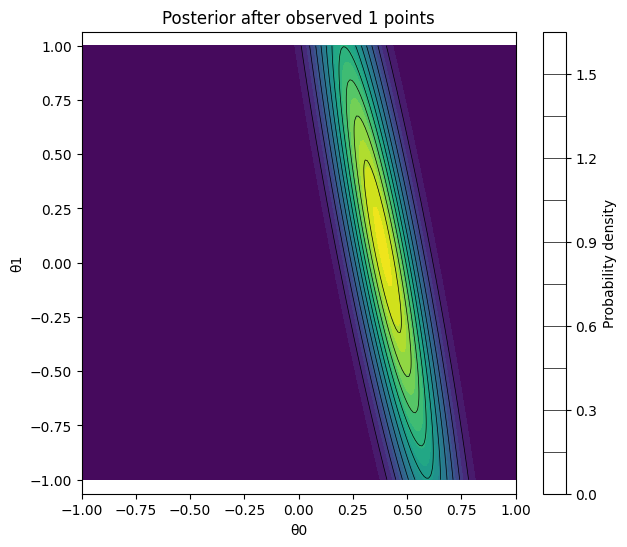

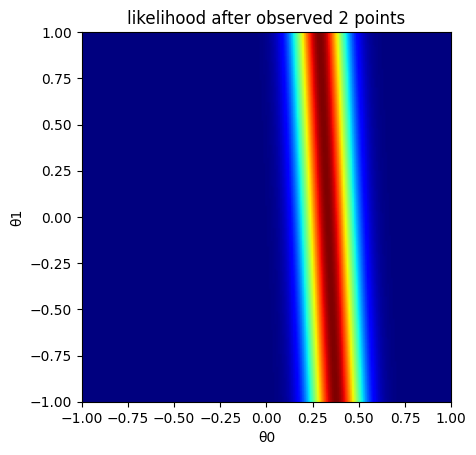

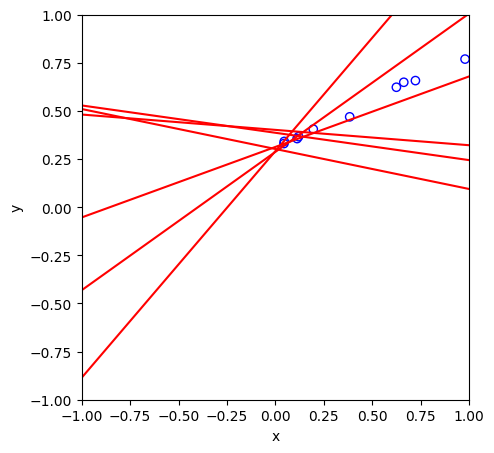

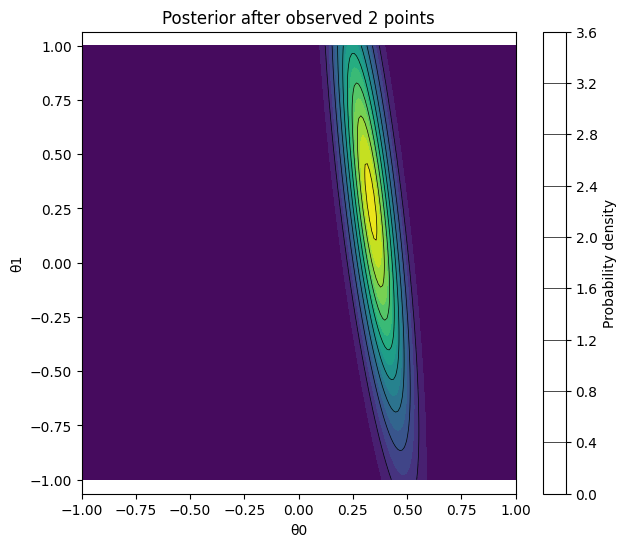

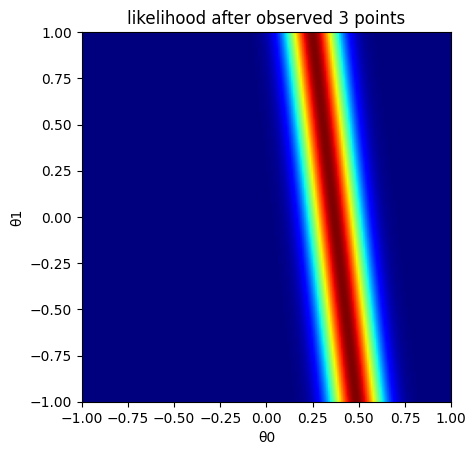

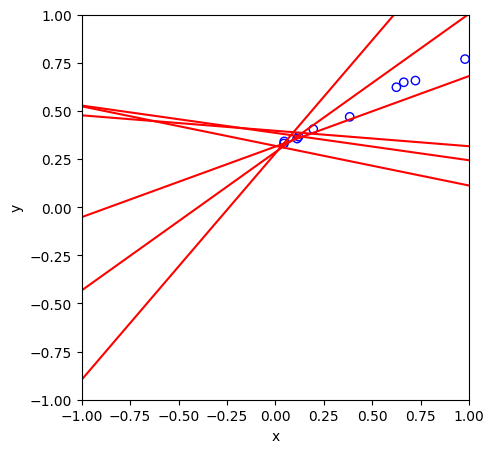

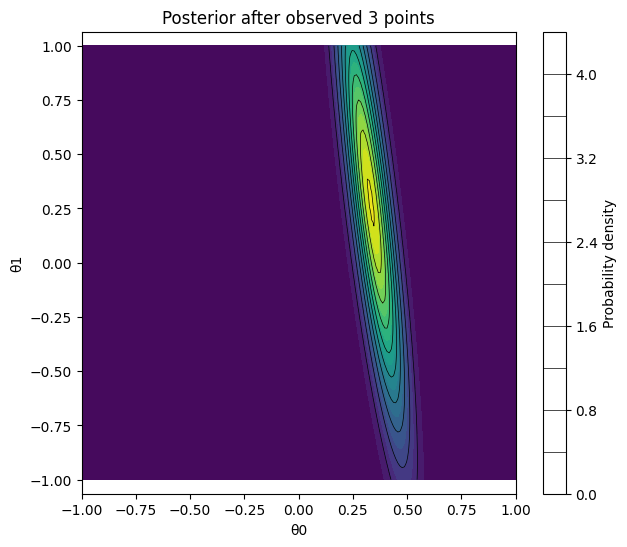

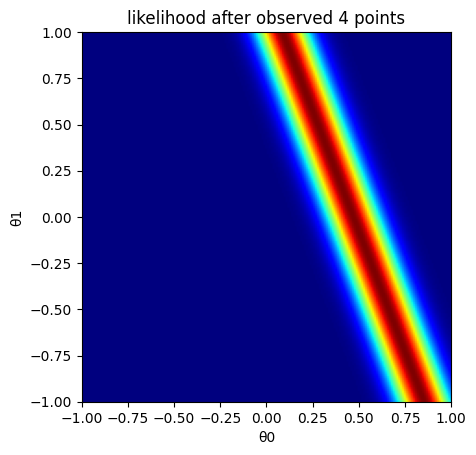

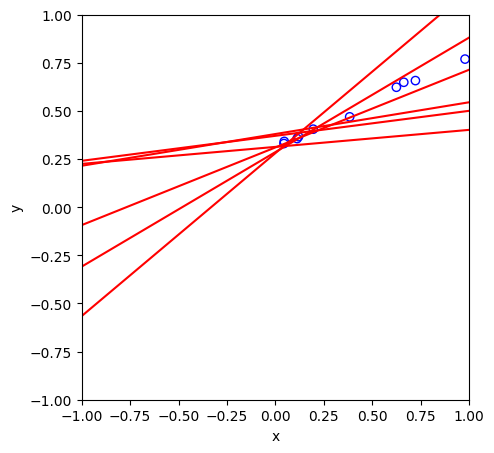

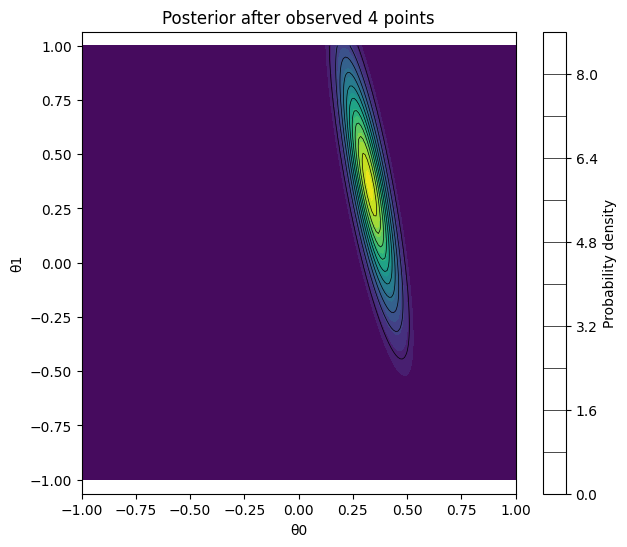

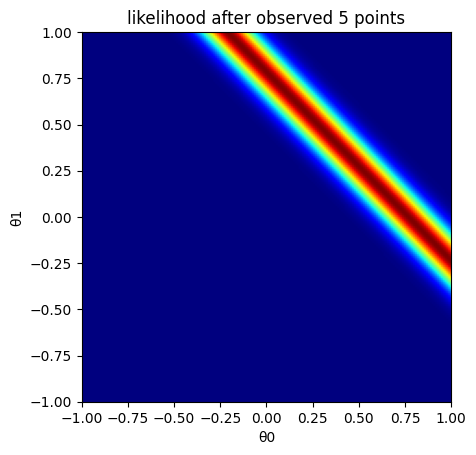

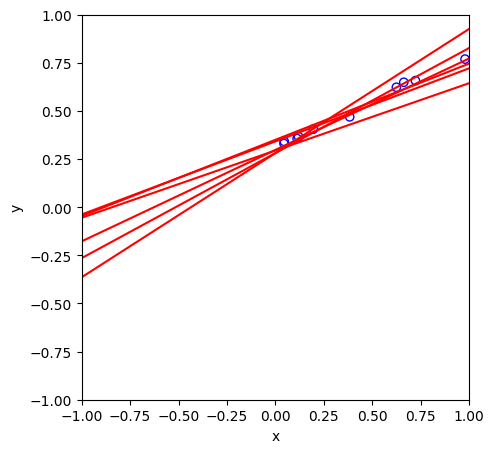

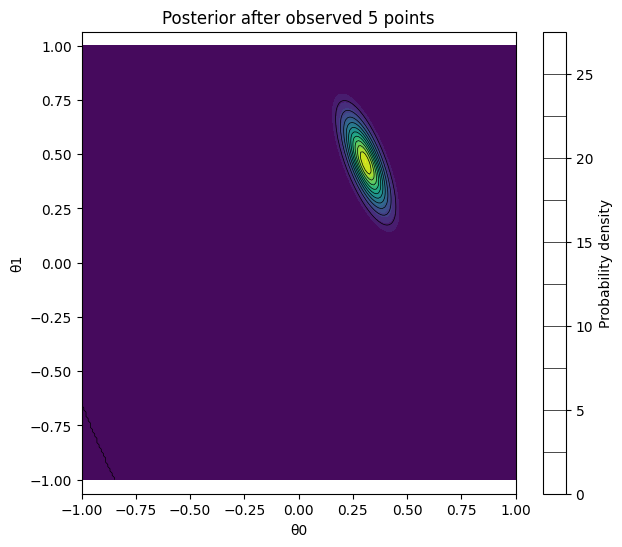

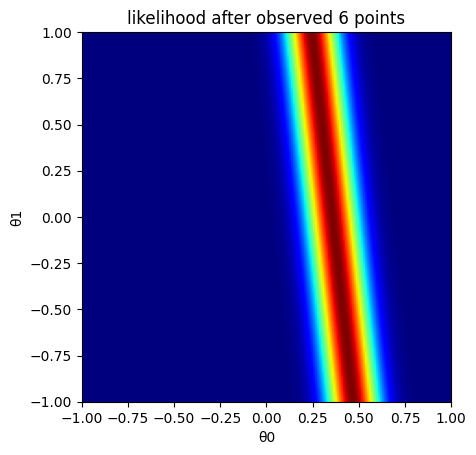

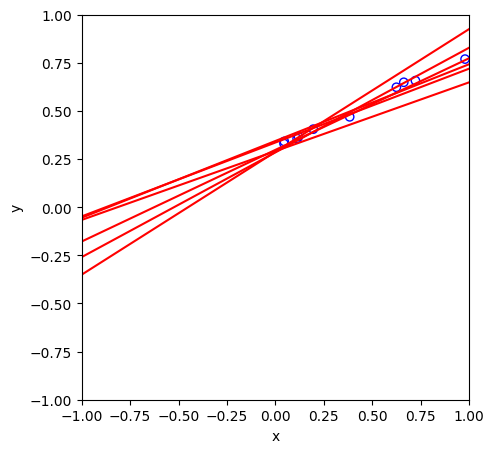

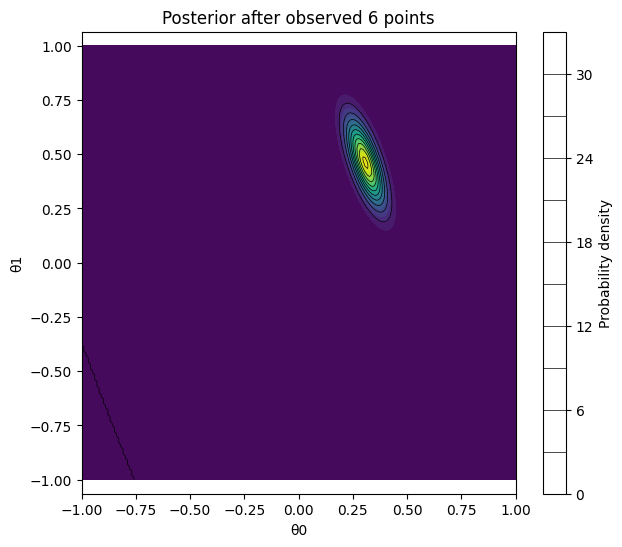

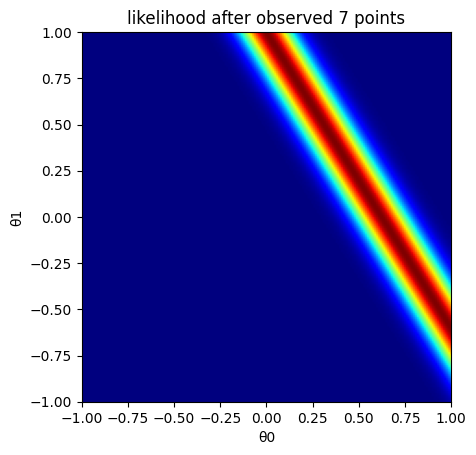

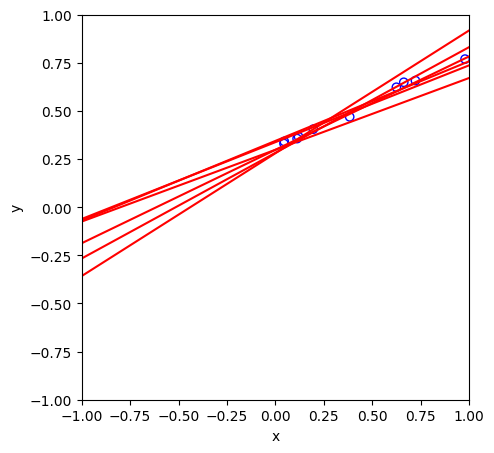

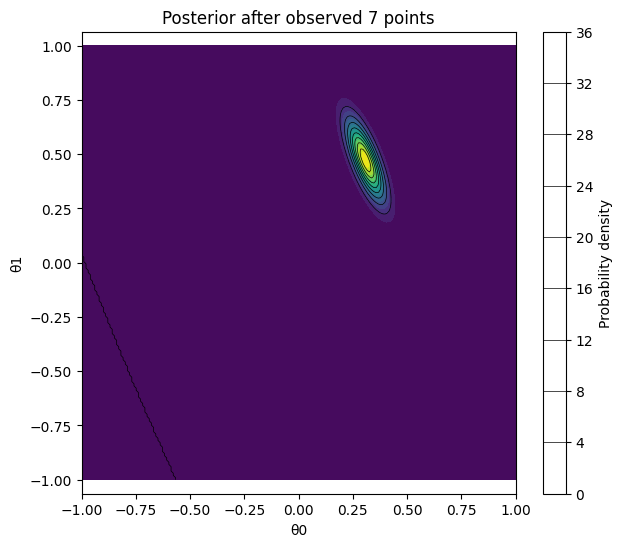

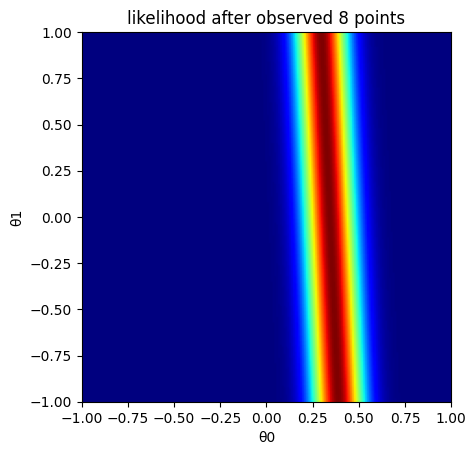

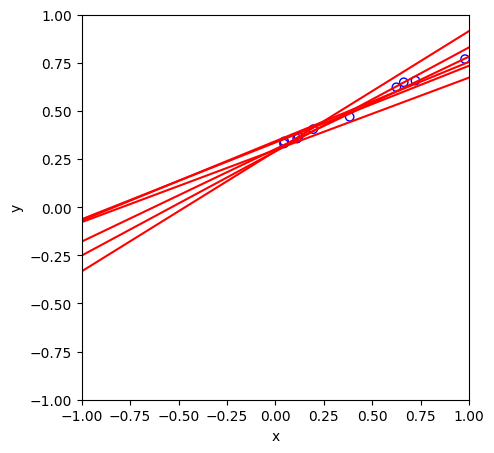

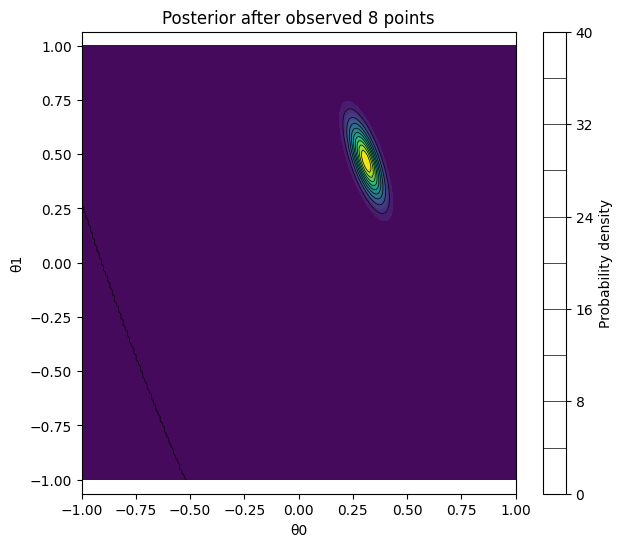

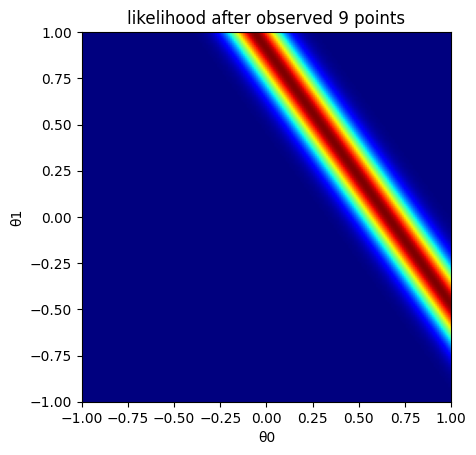

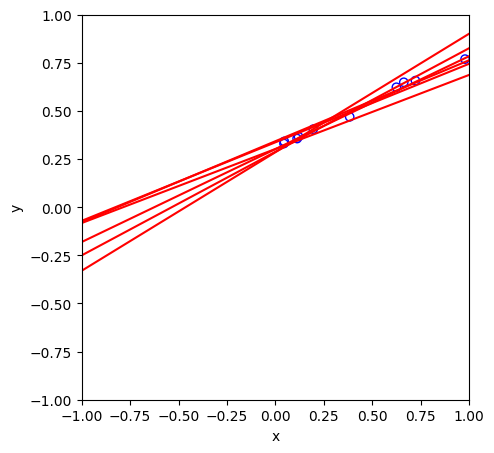

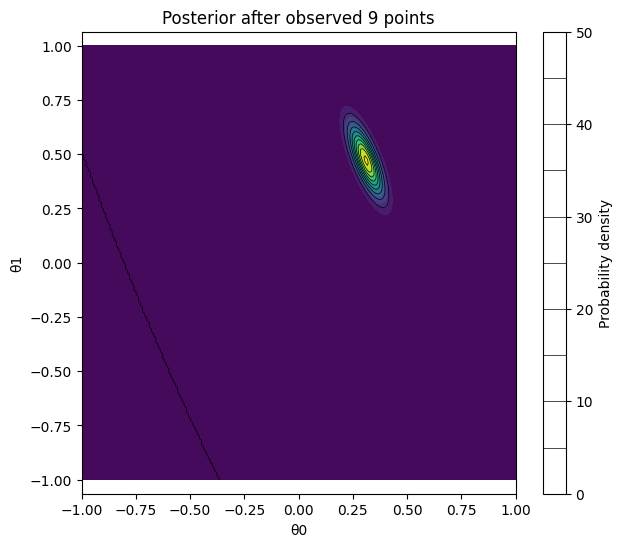

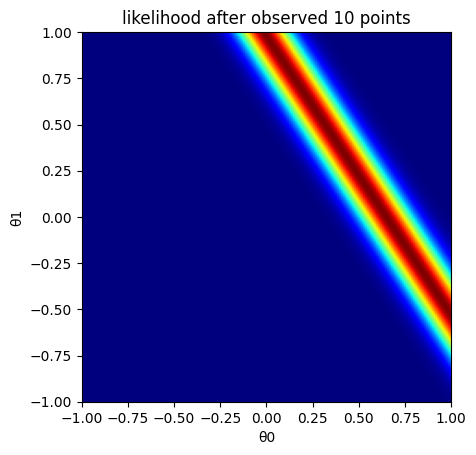

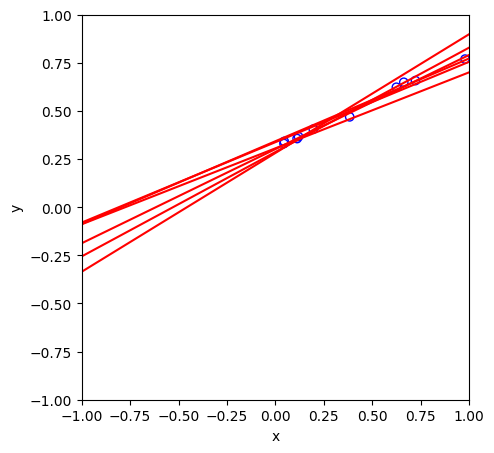

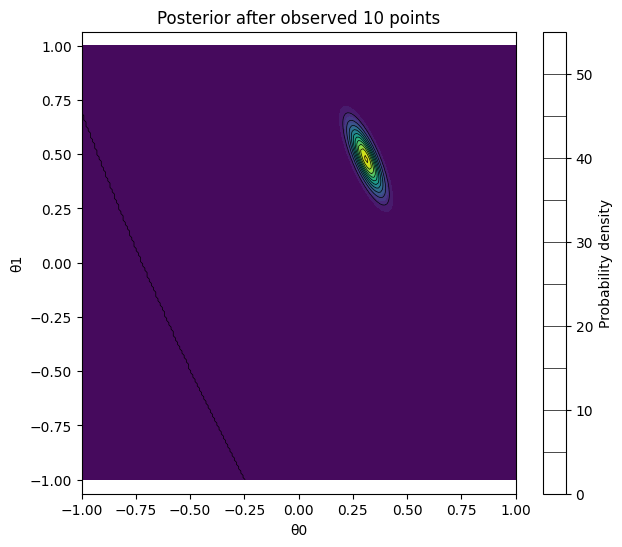

In [31]:
# Assume we generate a point abitrarily
x = np.random.sample(10)
var = 0.01
y = [linear_model(i, var) for i in x]
x = np.asarray(x, dtype=float).ravel()
y = np.asarray(y, dtype=float).ravel()
#The prior initial is 
mu = np.array([0, 1])
sigma = np.array([
    [1.0, 0],
    [0, 2. 0]
])
mu_k, sigma_k = mu, sigma
plot_multivariable_gauss_distribution(mu_k, sigma_k, f"Prior")
plot_data_space([], [], mu, sigma)
i = 0 
for xi, yi in zip(x, y):
    i+=1
    plot_likelihood([xi], [yi], var, f"likelihood after observed {i} points")          # cột likelihood: chỉ điểm mới
    mu_k, sigma_k = calculate_posterior_distribution([xi], [yi], mu_k, sigma_k, var)
    plot_data_space(x, y, mu_k, sigma_k)
    plot_multivariable_gauss_distribution(mu_k.T[0], sigma_k, f"Posterior after observed {i} points")  # cột giữa: tích lũy